# 🎥 Smart Video Background Blur

### Keep the person sharp. Blur the surroundings.

This notebook uses **YOLO segmentation** to find a person and **OpenCV** to blur everything outside the person's mask.

<div style="background:#eef6ff; padding:14px; border-radius:10px;">
<b>Our main rule</b><br>
⚪ White pixels in the mask = person (keep sharp)<br>
⚫ Black pixels in the mask = background (blur)
</div>


> **Important:** We will inspect the first frame before processing the full video. This helps us confirm that the person mask is white and the background is black.

## 1. Install the required libraries

In [1]:
!pip install -q ultralytics opencv-python matplotlib

## 2. Import libraries

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO
from IPython.display import Video, display

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


## 3. Set the configuration




In [3]:
VIDEO_PATH = "input_01.mp4"
OUTPUT_PATH = "smart_background_blur_01.mp4"
MODEL_PATH = "yolo26n-seg.pt"

## 4. Load the model and open the video


In [4]:
# Load a YOLO instance-segmentation model.
model = YOLO(MODEL_PATH)

# Open the input video.
cap = cv2.VideoCapture(VIDEO_PATH)

if not cap.isOpened():
    raise FileNotFoundError(f"Could not open video: {VIDEO_PATH}")

# Read the first frame for our preview.
ret, first_frame = cap.read()

if not ret:
    cap.release()
    raise ValueError("Could not read the first frame of the video.")

# Get the video properties.
height, width = first_frame.shape[:2]

print(f"Frame size: {width} x {height}")

Frame size: 1080 x 1920


## 5. Create the person's binary mask

A **mask** is a black-and-white image with the same height and width as the video frame.

- `255` (white) means the pixel belongs to the person.
- `0` (black) means the pixel belongs to the background.

YOLO returns a separate segmentation outline for each detected person. We draw each outline on a blank black image, measure the white area, and keep the largest person mask.

**Why use the mask?** It tells us exactly which pixels should stay sharp.

In [ ]:
# Original masks (shape = 2, 3, 3):

# Mask 1:             Mask 2:
# [[255, 0,   0],     [[0, 255, 0],
#  [  0, 0, 255],      [0,   0, 0],
#  [  0, 0,   0]]      [255, 0, 255]]


# axis=0: Combine both masks pixel by pixel.
# Result (3, 3):
# [[ True,  True, False],
#  [False, False,  True],
#  [ True, False,  True]]


# axis=1: Combine rows within each mask (vertically).
# Result (2, 3):
# [[ True, False,  True],   # Mask 1
#  [ True,  True,  True]]   # Mask 2


# axis=2: Combine columns within each mask (horizontally).
# Result (2, 3):
# [[ True,  True,  False],  # Mask 1
#  [ True, False,  True]]   # Mask 2

In [5]:
def create_person_mask(frame):

    # Detect all people.
    result = model.predict(
        source=frame,
        conf=0.5,
        classes=[0],
        verbose=False
    )[0]

    # If no person is detected, return a black mask.
    if result.masks is None:
        return np.zeros(frame.shape[:2], dtype=np.uint8)

    # Get all predicted masks.
    masks = result.masks.data.cpu().numpy()

    # Combine all person masks into one binary mask.
    person_mask = np.any(masks > 0, axis=0).astype(np.uint8) * 255

    # Resize the mask to match the original frame dimensions.
    person_mask = cv2.resize(person_mask, (frame.shape[1], frame.shape[0]))

    return person_mask

## 6. Generate and inspect the first-frame mask

Before blurring anything, run segmentation on the first frame and display the mask.


(1920, 1080)


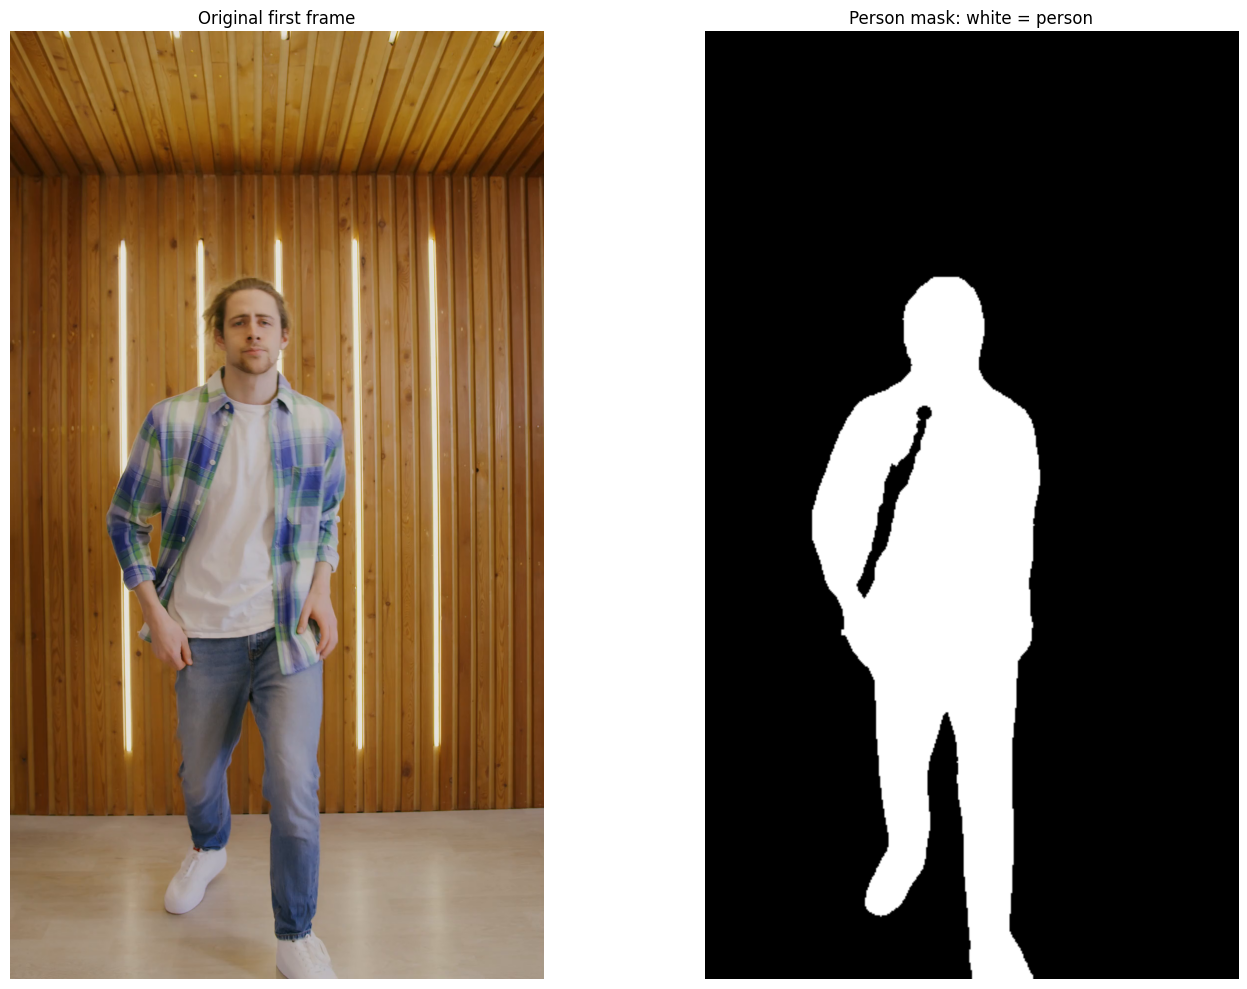

In [6]:
# Create the mask for the first frame.
first_person_mask = create_person_mask(first_frame)

# Display the original frame, binary mask, and mask overlay.
fig, axes = plt.subplots(1, 2, figsize=(15,10))

axes[0].imshow(cv2.cvtColor(first_frame, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original first frame")

axes[1].imshow(first_person_mask, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Person mask: white = person")

print(first_person_mask.shape)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 7. Create a blurred background and combine the layers



In [15]:
def apply_background_blur(frame, person_mask):

    # Blur the entire frame.
    blurred_frame = cv2.GaussianBlur(frame, (0, 0), 16)

    alpha = person_mask.astype(np.float32) / 255.0
    alpha = alpha[:, :, np.newaxis]

    # alpha = person_mask / 255
    # print(type(alpha[0][0]))
    # print(frame.shape)

    # Keep the person sharp and the background blurred.
    sharp_person = frame.astype(np.float32) * alpha
    blurred_background = blurred_frame.astype(np.float32) * (1 - alpha)

    # Combine both images.
    final_frame = sharp_person + blurred_background

    return final_frame.astype(np.uint8), blurred_frame


## 8. Preview the complete first-frame result


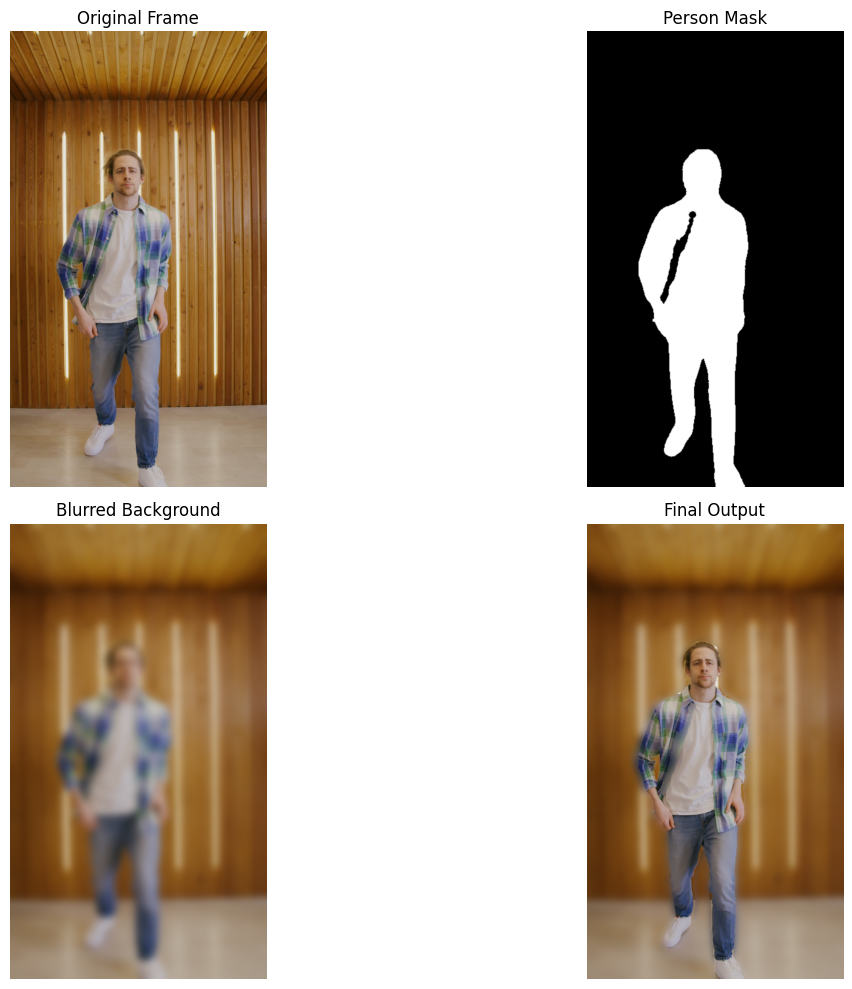

In [16]:
# Apply background blur.
first_output, first_blurred_frame = apply_background_blur(first_frame, first_person_mask)

# Display all four images.
plt.figure(figsize=(15,10))

plt.subplot(2, 2, 1)
plt.imshow(cv2.cvtColor(first_frame, cv2.COLOR_BGR2RGB))
plt.title("Original Frame")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(first_person_mask, cmap="gray")
plt.title("Person Mask")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(cv2.cvtColor(first_blurred_frame, cv2.COLOR_BGR2RGB))
plt.title("Blurred Background")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(cv2.cvtColor(first_output, cv2.COLOR_BGR2RGB))
plt.title("Final Output")
plt.axis("off")

plt.tight_layout()
plt.show()

## 9. Process the complete video

In [ ]:
from tqdm.notebook import tqdm

# Create video writer.
fps = cap.get(cv2.CAP_PROP_FPS)
fourcc = cv2.VideoWriter_fourcc(*"mp4v")
writer = cv2.VideoWriter(OUTPUT_PATH, fourcc, fps, (width, height))

if not writer.isOpened():
    raise RuntimeError("Could not create output video.")

# Get total frames and write the first processed frame.
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
writer.write(first_output)

# Process remaining frames.
with tqdm(total=total_frames, initial=1, desc="Processing Video") as pbar:

    while True:
        ret, frame = cap.read()

        if not ret:
            break

        person_mask = create_person_mask(frame)
        output_frame, _ = apply_background_blur(frame, person_mask)

        writer.write(output_frame)
        pbar.update(1)

# Release resources.
cap.release()
writer.release()

print(f"✅ Output saved to: {OUTPUT_PATH}")

Processing Video:   0%|          | 1/602 [00:00<?, ?it/s]

✅ Output saved to: smart_background_blur_02.mp4
